In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

https://www.data-to-viz.com/graph/ridgeline.html

https://python-graph-gallery.com/ridgeline-graph-seaborn/

In [2]:
# https://www.kaggle.com/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026/
df= pd.read_csv('data/track_metadata.csv')

In [3]:
df.head()

,track_id,track_title,artist_name,genre,release_date,is_explicit,duration_ms
0,track_0001,Hit Song 1,Artist 164,Hip-Hop,2026-06-26,1,219088
1,track_0002,Hit Song 2,Artist 29,K-Pop,2023-08-04,0,243281
2,track_0003,Hit Song 3,Artist 7,Rock,2025-01-05,0,207916
3,track_0004,Hit Song 4,Artist 190,Dance/Electronic,2022-12-16,0,172270
4,track_0005,Hit Song 5,Artist 71,Pop,2018-07-31,0,215476


In [4]:
df.groupby('genre')['duration_ms'].mean()

genre
Dance/Electronic     210852.091429
Hip-Hop              209121.004525
Indie/Alternative    205053.056452
K-Pop                211619.932203
Latin                209832.909091
Pop                  211817.198113
R&B                  210072.281250
Rock                 215041.972477
Name: duration_ms, dtype: float64

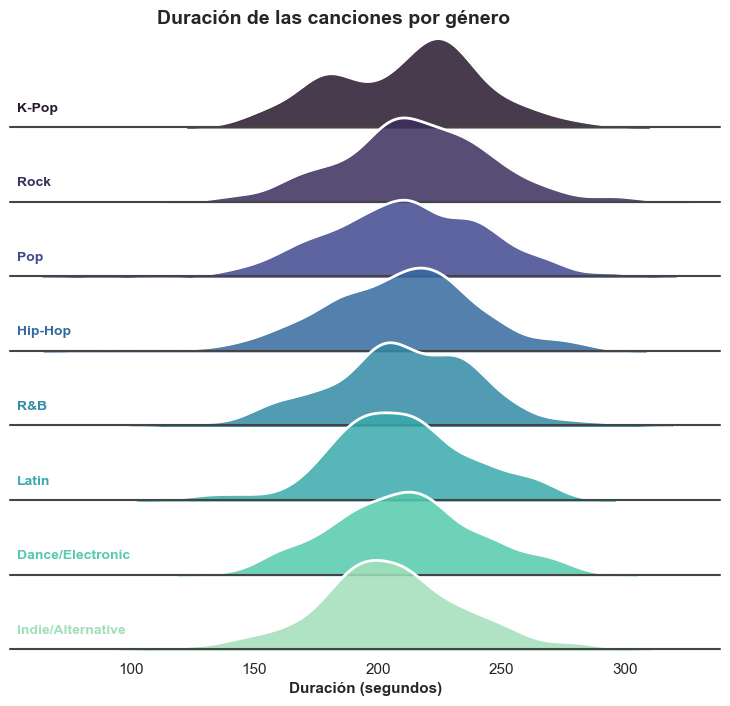

In [5]:
df['genre'] = df['genre'].replace('Indie\\/Alternative', 'Indie/Alternative').replace('Dance\\/Electronic', 'Dance/Electronic')
df['duration_s'] = df['duration_ms']/1000 # de milisegundos a segundos

# Ordenamos por duración media
genre_order = (
    df.groupby("genre")["duration_s"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

# Tema blanco y sin contornos
sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})
palette = sns.color_palette("mako", n_colors=len(genre_order))

# Usamos FacetGrid
g = sns.FacetGrid(
    df,
    row="genre",
    hue="genre",
    row_order=genre_order,
    hue_order=genre_order,
    aspect=9,
    height=0.9,
    palette=palette,
)

# Cada Ridgeline plot será realmente un KDE plot
g.map(
    sns.kdeplot,
    "duration_s",
    bw_adjust=0.8,
    clip_on=False,
    fill=True,
    alpha=0.85,
    linewidth=1.5,
)

# Línea blanca de contorno para cada KDE plot (para ver a traves del overlap)
g.map(sns.kdeplot,
      "duration_s",
      bw_adjust=0.8,
      clip_on=False,
      color="white",
      lw=2)

# Baseline line
g.refline(y=0, linewidth=1.5, linestyle="-", color="#444444", clip_on=False)


# Función para agregar las etiquetas de género a cada KDE plot
def add_genre_label(x, color, label):
    ax = plt.gca()
    ax.text(
        0.01,
        0.2,
        label,
        fontweight="bold",
        color=color,
        ha="left",
        va="center",
        transform=ax.transAxes,
        fontsize=10,
    )

g.map(add_genre_label, "duration_s")

# Overlap
g.figure.subplots_adjust(hspace=-0.2)
g.set_titles("")
g.set(yticks=[], ylabel="")
g.despine(bottom=True, left=True)


g.axes[-1, 0].set_xlabel("Duración (segundos)", fontweight="bold", fontsize=11)
g.figure.suptitle(
    "Duración de las canciones por género",
    y=0.98,
    fontsize=14,
    fontweight="bold",
)

# plt.savefig("img/joyplot.png")
plt.show()